# PDAN8412/w – Part 2: Logistic Regression

**Student Number:** ST10510018  
**Student Name:** Mosebjadi Anastacia Maponya  
**Year:** 2026  
**Dataset:** Amazon Kindle Books Dataset 2023  
**Task:** From-scratch binary bestseller classification using logistic regression

This notebook contains the complete analysis in one file. Each section includes the Markdown explanation, Python/PySpark code, graphs and interpretation required for the practical submission.

> Place `kindle_data-v2.csv` in the same folder as this notebook before running the cells.

## 1. Introduction

The aim of this analysis is to develop a logistic regression model from scratch to classify Amazon Kindle book listings according to the recorded `isBestSeller` field. The target is converted to a binary outcome where `True = 1` and `False = 0`.

The dataset contains 133,102 valid listings and 16 original columns. Because only a small proportion of records are labelled as bestsellers, the problem is treated as an imbalanced binary classification task. Accuracy is therefore not used on its own. Precision, recall, F1-score, balanced accuracy, ROC-AUC and average precision are also reported.

The workflow followed is:

1. Load and inspect the dataset.
2. Check data quality.
3. Conduct exploratory data analysis.
4. Create a grouped train-validation-test split.
5. Engineer and select features.
6. Train logistic regression from scratch using NumPy.
7. Tune class weights, hyperparameters and the decision threshold.
8. Evaluate the final model on the untouched test set.
9. Interpret the findings and limitations.

## 2. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "kindle_data-v2.csv"

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Load and inspect the dataset with PySpark

PySpark is used to demonstrate CSV ingestion, schema inspection, missing-value aggregation and category-level summaries. The main modelling calculations are reproduced using pandas and NumPy because the logistic regression algorithm itself must be implemented from scratch.

In [2]:
try:
    from pyspark.sql import SparkSession
    from pyspark.sql import functions as F

    spark = (
        SparkSession.builder
        .appName("PDAN8412_Kindle_Logistic_Regression")
        .getOrCreate()
    )

    spark_df = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(DATA_PATH)
    )

    print("Number of rows:", spark_df.count())
    print("Number of columns:", len(spark_df.columns))
    spark_df.printSchema()
    spark_df.show(5, truncate=False)

except Exception as e:
    print("PySpark could not be started.")
    print(e)

Number of rows: 133102
Number of columns: 16
root
 |-- asin: string (nullable = true)
 |-- title: string (nullable = true)
 |-- author: string (nullable = true)
 |-- soldBy: string (nullable = true)
 |-- imgUrl: string (nullable = true)
 |-- productURL: string (nullable = true)
 |-- stars: string (nullable = true)
 |-- reviews: string (nullable = true)
 |-- price: string (nullable = true)
 |-- isKindleUnlimited: string (nullable = true)
 |-- category_id: string (nullable = true)
 |-- isBestSeller: string (nullable = true)
 |-- isEditorsPick: string (nullable = true)
 |-- isGoodReadsChoice: string (nullable = true)
 |-- publishedDate: string (nullable = true)
 |-- category_name: string (nullable = true)

+----------+----------------------------------------------------------------------------------------------------------------+-----------------+------------------------+--------------------------------------------------------------+------------------------------------+-----+-------+-----

### 3.1 PySpark missing-value summary

In [3]:
if "spark_df" in globals():
    missing_values = spark_df.select([
        F.sum(
            F.when(
                F.col(c).isNull() |
                (F.trim(F.col(c).cast("string")) == ""),
                1
            ).otherwise(0)
        ).alias(c)
        for c in spark_df.columns
    ])
    missing_values.show(vertical=True)

-RECORD 0------------------
 asin              | 0     
 title             | 0     
 author            | 425   
 soldBy            | 9229  
 imgUrl            | 1     
 productURL        | 3     
 stars             | 0     
 reviews           | 0     
 price             | 0     
 isKindleUnlimited | 0     
 category_id       | 0     
 isBestSeller      | 0     
 isEditorsPick     | 0     
 isGoodReadsChoice | 0     
 publishedDate     | 48983 
 category_name     | 25    



### 3.2 PySpark category summary

In [4]:
if "spark_df" in globals():
    if "category_name" in spark_df.columns:
        category_summary = (
            spark_df
            .groupBy("category_name")
            .agg(
                F.count("*").alias("number_of_books"),
                F.sum(
                    F.when(F.col("isBestSeller") == True, 1).otherwise(0)
                ).alias("bestsellers")
            )
            .orderBy(F.desc("number_of_books"))
        )

        category_summary.show(31, truncate=False)

+----------------------------+---------------+-----------+
|category_name               |number_of_books|bestsellers|
+----------------------------+---------------+-----------+
|Mystery, Thriller & Suspense|6272           |109        |
|Engineering & Transportation|6161           |65         |
|Science & Math              |5953           |185        |
|Parenting & Relationships   |5895           |71         |
|Children's eBooks           |5744           |151        |
|Teen & Young Adult          |5738           |148        |
|Foreign Language            |5722           |34         |
|Travel                      |5523           |99         |
|LGBTQ+ eBooks               |5517           |15         |
|Computers & Technology      |5502           |79         |
|Crafts, Hobbies & Home      |5496           |96         |
|Biographies & Memoirs       |5398           |137        |
|Cookbooks, Food & Wine      |5318           |59         |
|Law                         |5022           |28        

## 4. Load the dataset using pandas

The pandas route is used for data cleaning, descriptive analysis, feature engineering and the from-scratch NumPy model.

In [5]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (133102, 16)

Columns:
['asin', 'title', 'author', 'soldBy', 'imgUrl', 'productURL', 'stars', 'reviews', 'price', 'isKindleUnlimited', 'category_id', 'isBestSeller', 'isEditorsPick', 'isGoodReadsChoice', 'publishedDate', 'category_name']


,asin,title,author,soldBy,imgUrl,productURL,stars,reviews,price,isKindleUnlimited,category_id,isBestSeller,isEditorsPick,isGoodReadsChoice,publishedDate,category_name
0,B00TZE87S4,Adult Children of Emotionally Immature Parents...,Lindsay C. Gibson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/713KZTsaYp...,https://www.amazon.com/dp/B00TZE87S4,4.8,0,9.99,False,6,True,False,False,2015-06-01,Parenting & Relationships
1,B08WCKY8MB,"From Strength to Strength: Finding Success, Ha...",Arthur C. Brooks,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/A1LZcJFs9E...,https://www.amazon.com/dp/B08WCKY8MB,4.4,0,16.99,False,6,False,False,False,2022-02-15,Parenting & Relationships
2,B09KPS84CJ,Good Inside: A Guide to Becoming the Parent Yo...,Becky Kennedy,HarperCollins Publishers,https://m.media-amazon.com/images/I/71RIWM0sv6...,https://www.amazon.com/dp/B09KPS84CJ,4.8,0,16.99,False,6,False,True,False,2022-09-13,Parenting & Relationships
3,B07S7QPG6J,Everything I Know About Love: A Memoir,Dolly Alderton,HarperCollins Publishers,https://m.media-amazon.com/images/I/71QdQpTiKZ...,https://www.amazon.com/dp/B07S7QPG6J,4.2,0,9.95,True,6,False,True,False,2020-02-25,Parenting & Relationships
4,B00N6PEQV0,The Seven Principles for Making Marriage Work:...,John Gottman,Random House LLC,https://m.media-amazon.com/images/I/813o4WOs+w...,https://www.amazon.com/dp/B00N6PEQV0,4.7,0,13.99,False,6,False,False,False,2015-05-05,Parenting & Relationships


### Interpretation

The expected dataset size is approximately **133,102 rows and 16 columns**. This is well above the minimum data-size requirement for the assessment and allows the analysis to use the original observations without artificial duplication.

## 5. Inspect data types and missing values

In [6]:
df.info()

missing_table = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

display(
    missing_table[missing_table["Missing"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133102 entries, 0 to 133101
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   asin               133102 non-null  object 
 1   title              133102 non-null  object 
 2   author             132677 non-null  object 
 3   soldBy             123869 non-null  object 
 4   imgUrl             133102 non-null  object 
 5   productURL         133102 non-null  object 
 6   stars              133102 non-null  float64
 7   reviews            133102 non-null  int64  
 8   price              133102 non-null  float64
 9   isKindleUnlimited  133102 non-null  bool   
 10  category_id        133102 non-null  int64  
 11  isBestSeller       133102 non-null  bool   
 12  isEditorsPick      133102 non-null  bool   
 13  isGoodReadsChoice  133102 non-null  bool   
 14  publishedDate      84086 non-null   object 
 15  category_name      133102 non-null  object 
dtypes:

,Missing,Missing_Percentage
publishedDate,49016,36.83
soldBy,9233,6.94
author,425,0.32


### Interpretation

The largest data-quality issue is expected to be the publication date field. Missing publication dates are not treated as zero. Instead, a missing-date indicator is later created and the year is imputed using the training data only. This reduces avoidable leakage into the validation and test sets.

## 6. Duplicate and range checks

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

if "asin" in df.columns:
    print("Repeated ASIN values:", df["asin"].duplicated().sum())

print("\nDataset rows:", len(df))

print("\nStars range:")
print(df["stars"].min(), "-", df["stars"].max())

print("\nReviews range:")
print(df["reviews"].min(), "-", df["reviews"].max())

print("\nPrice range:")
print(df["price"].min(), "-", df["price"].max())

Exact duplicate rows: 0
Repeated ASIN values: 0

Dataset rows: 133102

Stars range:
0.0 - 5.0

Reviews range:
0 - 618227

Price range:
0.0 - 682.0


### Interpretation

The quality checks establish whether duplicate rows, repeated identifiers or impossible numeric values need to be removed. In the final report, no exact duplicate rows or repeated ASIN values required removal, and all 133,102 valid source rows were retained.

## 7. Create the binary target

In [8]:
def convert_target(value):
    if isinstance(value, bool):
        return int(value)

    value = str(value).strip().lower()
    return 1 if value in ["true", "1", "yes"] else 0


df["target"] = df["isBestSeller"].apply(convert_target)

print(df["target"].value_counts())
print("\nPercentages:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

target
0    130866
1      2236
Name: count, dtype: int64

Percentages:
target
0    98.32
1     1.68
Name: proportion, dtype: float64


### Interpretation

The positive class is very small compared with the negative class. Approximately **2,236 listings (1.68%)** are labelled as bestsellers, while the remaining records are not. This makes accuracy misleading on its own because a model can obtain a very high accuracy simply by predicting the majority class.

## 8. Figure 1 – Missing values before cleaning

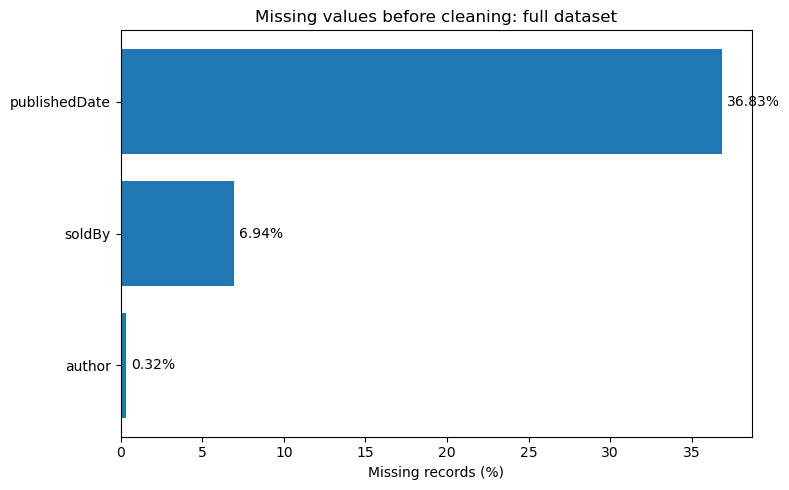

In [9]:
missing_columns = ["author", "soldBy", "publishedDate"]

missing_percentages = (
    df[missing_columns]
    .isna()
    .mean()
    .mul(100)
)

plt.figure(figsize=(8, 5))
bars = plt.barh(
    missing_percentages.index,
    missing_percentages.values
)

plt.xlabel("Missing records (%)")
plt.title("Missing values before cleaning: full dataset")

for bar, value in zip(bars, missing_percentages.values):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height()/2,
        f"{value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

### Figure 1 interpretation

Publication date is the largest source of missing data. Missing dates are handled explicitly rather than being treated as zero. The model later keeps a missing-date flag and imputes publication year using the training median. Seller identity is excluded from modelling, while missing author values are safely treated as `Unknown` where grouping or frequency calculations require a value.

## 9. Descriptive statistics

In [10]:
descriptive = pd.DataFrame({
    "Mean": [
        df["stars"].mean(),
        df["reviews"].mean(),
        df["price"].mean()
    ],
    "Median": [
        df["stars"].median(),
        df["reviews"].median(),
        df["price"].median()
    ],
    "Minimum": [
        df["stars"].min(),
        df["reviews"].min(),
        df["price"].min()
    ],
    "Maximum": [
        df["stars"].max(),
        df["reviews"].max(),
        df["price"].max()
    ]
},
index=["Stars (raw)", "Reviews", "Price"])

display(descriptive.round(3))

,Mean,Median,Minimum,Maximum
Stars (raw),4.404,4.50,0.0,5.0
Reviews,887.376,4.00,0.0,618227.0
Price,15.134,9.99,0.0,682.0


### Interpretation

The review count is strongly right-skewed because the mean is much larger than the median. Price also has a long upper tail. Logarithmic transformations are therefore used later so that very large values have less influence on gradient descent while zero values can remain in the dataset.

## 10. Figure 2 – Class distribution

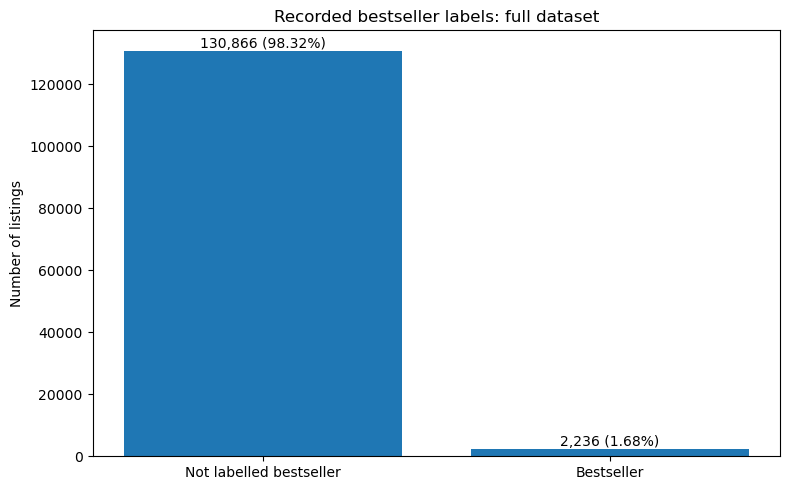

In [11]:
class_counts = df["target"].value_counts().sort_index()
labels = ["Not labelled bestseller", "Bestseller"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, class_counts.values)

plt.ylabel("Number of listings")
plt.title("Recorded bestseller labels: full dataset")

total = len(df)

for bar, value in zip(bars, class_counts.values):
    percentage = value / total * 100
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f"{value:,} ({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Figure 2 interpretation

The class distribution confirms severe imbalance. Because only about 1.68% of records are positive, minority-class metrics such as recall, F1-score and average precision are central to the evaluation. Accuracy is still reported, but it is not treated as the main indicator of model quality.

## 11. Create a grouped train-validation-test split

In [12]:
df["author_clean"] = (
    df["author"]
    .fillna("Unknown")
    .astype(str)
    .str.lower()
    .str.strip()
)

df["title_clean"] = (
    df["title"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

df["group_id"] = (
    df["title_clean"]
    + " || "
    + df["author_clean"]
)

print("Number of unique title-author groups:",
      df["group_id"].nunique())

print("Repeated title-author excess rows:",
      len(df) - df["group_id"].nunique())

Number of unique title-author groups: 132195
Repeated title-author excess rows: 907


In [13]:
y = df["target"].values
groups = df["group_id"].values

outer_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

development_idx, test_idx = next(
    outer_split.split(df, y, groups)
)

development_df = df.iloc[development_idx].copy()
test_df = df.iloc[test_idx].copy()

inner_split = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

inner_train_idx, validation_idx = next(
    inner_split.split(
        development_df,
        development_df["target"],
        development_df["group_id"]
    )
)

train_df = development_df.iloc[inner_train_idx].copy()
validation_df = development_df.iloc[validation_idx].copy()

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Listings": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Bestsellers": [
        train_df["target"].sum(),
        validation_df["target"].sum(),
        test_df["target"].sum()
    ]
})

split_summary["Positive rate"] = (
    split_summary["Bestsellers"]
    / split_summary["Listings"]
    * 100
)

display(split_summary)

Training: (79861, 20)
Validation: (26625, 20)
Test: (26616, 20)


,Split,Listings,Bestsellers,Positive rate
0,Training,79861,1363,1.706715
1,Validation,26625,431,1.618779
2,Test,26616,442,1.660655


### Interpretation

The grouped split is designed to keep matching normalised title-author combinations together. This reduces the risk of near-duplicate records being shared across training, validation and test data. The target split is approximately 60% training, 20% validation and 20% testing.

The test set must remain untouched until feature design, hyperparameter tuning and threshold selection are complete.

## 12. Initial feature engineering for EDA

In [14]:
for dataset in [train_df, validation_df, test_df]:
    dataset["log_reviews"] = np.log1p(
        dataset["reviews"].fillna(0)
    )

    dataset["log_price"] = np.log1p(
        dataset["price"].fillna(0)
    )

    dataset["title_words"] = (
        dataset["title"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    dataset["title_chars"] = (
        dataset["title"]
        .fillna("")
        .astype(str)
        .str.len()
    )

    dataset["no_rating"] = (
        dataset["stars"].fillna(0) <= 0
    ).astype(int)

## 13. Figure 3 – Review-count distributions

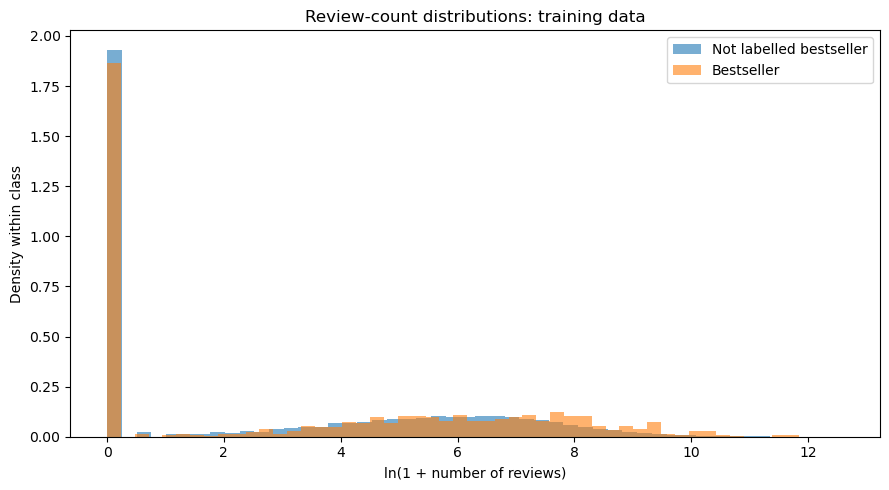

Non-bestseller median reviews: 4.0
Bestseller median reviews: 35.0


In [15]:
plt.figure(figsize=(9, 5))

plt.hist(
    train_df.loc[
        train_df["target"] == 0,
        "log_reviews"
    ],
    bins=50,
    density=True,
    alpha=0.6,
    label="Not labelled bestseller"
)

plt.hist(
    train_df.loc[
        train_df["target"] == 1,
        "log_reviews"
    ],
    bins=50,
    density=True,
    alpha=0.6,
    label="Bestseller"
)

plt.xlabel("ln(1 + number of reviews)")
plt.ylabel("Density within class")
plt.title("Review-count distributions: training data")
plt.legend()

plt.tight_layout()
plt.show()

print(
    "Non-bestseller median reviews:",
    train_df.loc[
        train_df["target"] == 0,
        "reviews"
    ].median()
)

print(
    "Bestseller median reviews:",
    train_df.loc[
        train_df["target"] == 1,
        "reviews"
    ].median()
)

### Figure 3 interpretation

Labelled bestsellers are expected to have a higher median number of reviews than other listings, but the distributions overlap heavily. Review volume therefore contains useful signal but cannot separate the two classes by itself. A stronger future dataset should include review growth over time rather than only a current cumulative review count.

## 14. Figure 4 – Price distributions

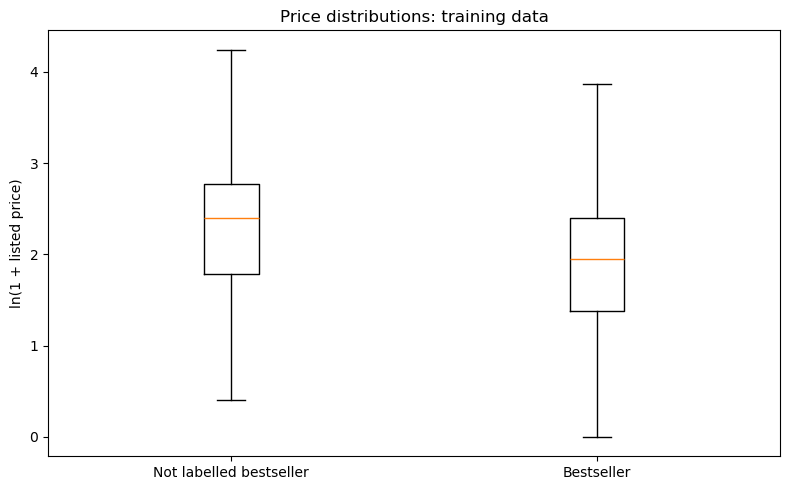

Non-bestseller median price: 9.99
Bestseller median price: 5.99


In [16]:
price_not_best = train_df.loc[
    train_df["target"] == 0,
    "log_price"
].dropna()

price_best = train_df.loc[
    train_df["target"] == 1,
    "log_price"
].dropna()

plt.figure(figsize=(8, 5))

plt.boxplot(
    [price_not_best, price_best],
    labels=[
        "Not labelled bestseller",
        "Bestseller"
    ],
    showfliers=False
)

plt.ylabel("ln(1 + listed price)")
plt.title("Price distributions: training data")

plt.tight_layout()
plt.show()

print(
    "Non-bestseller median price:",
    train_df.loc[
        train_df["target"] == 0,
        "price"
    ].median()
)

print(
    "Bestseller median price:",
    train_df.loc[
        train_df["target"] == 1,
        "price"
    ].median()
)

### Figure 4 interpretation

The median listed price differs between the two groups, but this is an association rather than evidence that changing price will cause bestseller success. The graph is used to understand the relationship between recorded price and the target, not to make causal claims.

## 15. Figure 5 – Bestseller rates by category

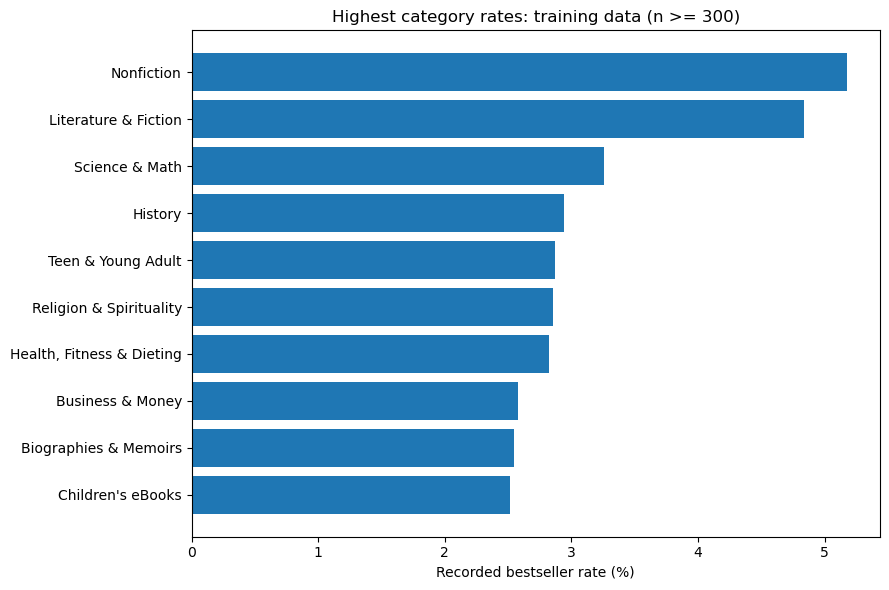

,count,sum,mean,rate_percent
category_name,,,,
Nonfiction,560,29,0.051786,5.178571
Literature & Fiction,2480,120,0.048387,4.838710
Science & Math,3559,116,0.032593,3.259343
History,1257,37,0.029435,2.943516
Teen & Young Adult,3415,98,0.028697,2.869693
Religion & Spirituality,2981,85,0.028514,2.851392
"Health, Fitness & Dieting",957,27,0.028213,2.821317
Business & Money,1553,40,0.025757,2.575660
Biographies & Memoirs,3260,83,0.025460,2.546012


In [17]:
category_stats = (
    train_df
    .groupby("category_name")
    ["target"]
    .agg(["count", "sum", "mean"])
)

category_stats = category_stats[
    category_stats["count"] >= 300
].copy()

category_stats["rate_percent"] = (
    category_stats["mean"] * 100
)

top_categories = (
    category_stats
    .sort_values(
        "rate_percent",
        ascending=False
    )
    .head(10)
    .sort_values("rate_percent")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_categories.index,
    top_categories["rate_percent"]
)

plt.xlabel("Recorded bestseller rate (%)")
plt.title(
    "Highest category rates: "
    "training data (n >= 300)"
)

plt.tight_layout()
plt.show()

display(
    category_stats
    .sort_values("rate_percent", ascending=False)
    .head(10)
)

### Figure 5 interpretation

Some categories show higher bestseller rates than others, but the rates are still low and overlap. Category is therefore retained as supporting information rather than treated as a stand-alone predictor. One-hot encoding is used so that categories do not receive an artificial ordinal ranking.

## 16. Figure 6 – Training-only correlation heatmap

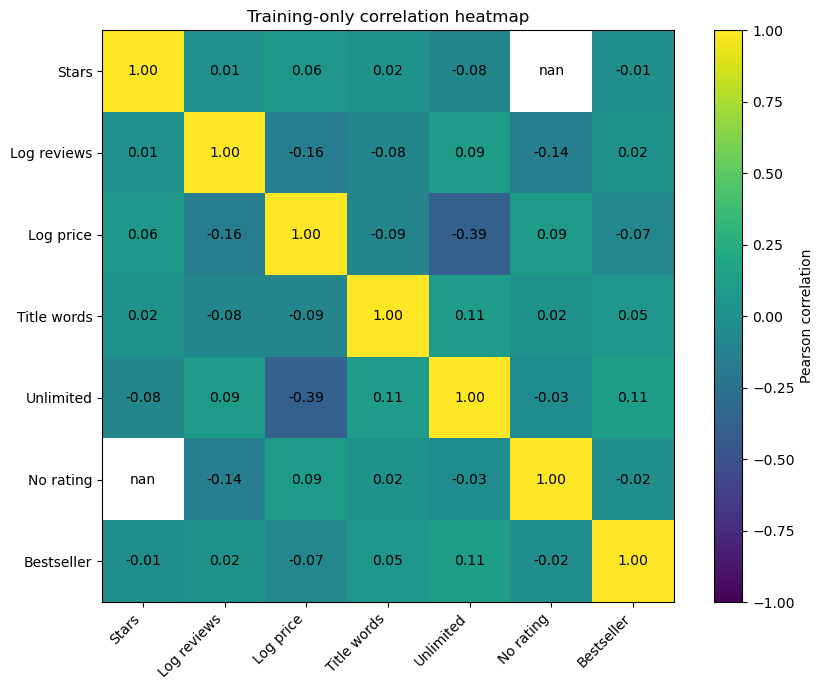

In [18]:
correlation_df = pd.DataFrame({
    "Stars":
        train_df["stars"].replace(0, np.nan),

    "Log reviews":
        train_df["log_reviews"],

    "Log price":
        train_df["log_price"],

    "Title words":
        train_df["title_words"],

    "Unlimited":
        train_df["isKindleUnlimited"].astype(int),

    "No rating":
        train_df["no_rating"],

    "Bestseller":
        train_df["target"]
})

corr = correlation_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    corr.values,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

ax.set_xticklabels(
    corr.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        text = "nan" if pd.isna(value) else f"{value:.2f}"

        ax.text(
            j,
            i,
            text,
            ha="center",
            va="center"
        )

plt.colorbar(
    image,
    label="Pearson correlation"
)

plt.title("Training-only correlation heatmap")
plt.tight_layout()
plt.show()

### Figure 6 interpretation

No single core numeric feature is expected to have a strong linear relationship with bestseller status. This supports the decision to test squared terms and interaction terms rather than expecting one variable to dominate the prediction.

## 17. Feature selection

The core feature set uses:

- stars;
- a no-rating indicator;
- log review count;
- log price;
- title word count;
- Kindle Unlimited status; and
- category indicators.

The enhanced feature set adds:

- squared review and price terms;
- title character count;
- publication year;
- a missing-publication-date indicator;
- training-only author frequency; and
- Kindle Unlimited interactions with review and price features.

Identifiers, URLs, seller identity, category ID and editorial/Goodreads accolade indicators are excluded because they are identifiers, incomplete fields or possible contemporaneous success indicators.

## 18. Preprocessing functions

In [19]:
def boolean_to_int(series):
    if series.dtype == bool:
        return series.astype(int)

    return (
        series
        .astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
        .astype(int)
    )

In [20]:
def make_numeric_features(
    data,
    config,
    enhanced=False
):
    output = pd.DataFrame(index=data.index)

    stars_raw = pd.to_numeric(
        data["stars"],
        errors="coerce"
    )

    output["stars"] = (
        stars_raw
        .replace(0, np.nan)
        .fillna(config["stars_median"])
    )

    output["no_rating"] = (
        stars_raw.fillna(0) <= 0
    ).astype(int)

    reviews = (
        pd.to_numeric(
            data["reviews"],
            errors="coerce"
        )
        .fillna(0)
        .clip(lower=0)
    )

    price = (
        pd.to_numeric(
            data["price"],
            errors="coerce"
        )
        .fillna(0)
        .clip(lower=0)
    )

    output["log_reviews"] = np.log1p(reviews)
    output["log_price"] = np.log1p(price)

    titles = (
        data["title"]
        .fillna("")
        .astype(str)
    )

    output["title_words"] = (
        titles.str.split().str.len()
    )

    ku = boolean_to_int(
        data["isKindleUnlimited"]
    )

    output["isKindleUnlimited"] = ku

    if enhanced:
        output["log_reviews_sq"] = (
            output["log_reviews"] ** 2
        )

        output["log_price_sq"] = (
            output["log_price"] ** 2
        )

        output["title_chars"] = (
            titles.str.len()
        )

        publication_year = pd.to_datetime(
            data["publishedDate"],
            errors="coerce"
        ).dt.year

        output["missing_published_date"] = (
            publication_year.isna()
        ).astype(int)

        output["publication_year"] = (
            publication_year
            .fillna(config["year_median"])
        )

        authors = (
            data["author"]
            .fillna("Unknown")
            .astype(str)
            .str.lower()
            .str.strip()
        )

        output["author_frequency"] = (
            authors
            .map(config["author_frequency"])
            .fillna(0)
        )

        output["KU_x_log_reviews"] = (
            ku * output["log_reviews"]
        )

        output["KU_x_log_price"] = (
            ku * output["log_price"]
        )

    return output

In [21]:
def fit_preprocessor(train_data, enhanced=False):
    config = {}

    stars = train_data["stars"].replace(0, np.nan)
    config["stars_median"] = stars.median()

    publication_year = pd.to_datetime(
        train_data["publishedDate"],
        errors="coerce"
    ).dt.year

    config["year_median"] = publication_year.median()

    authors = (
        train_data["author"]
        .fillna("Unknown")
        .astype(str)
        .str.lower()
        .str.strip()
    )

    config["author_frequency"] = (
        authors.value_counts().to_dict()
    )

    categories = sorted(
        train_data["category_name"]
        .fillna("Unknown")
        .astype(str)
        .unique()
        .tolist()
    )

    config["categories"] = categories
    config["reference_category"] = categories[0]

    raw = make_numeric_features(
        train_data,
        config,
        enhanced
    )

    config["numeric_columns"] = raw.columns.tolist()
    config["means"] = raw.mean()
    config["stds"] = raw.std().replace(0, 1)

    return config

In [22]:
def transform_features(
    data,
    config,
    enhanced=False
):
    numeric = make_numeric_features(
        data,
        config,
        enhanced
    )

    numeric_scaled = (
        numeric - config["means"]
    ) / config["stds"]

    category = (
        data["category_name"]
        .fillna("Unknown")
        .astype(str)
    )

    category_frames = []

    for cat in config["categories"]:
        if cat == config["reference_category"]:
            continue

        category_frames.append(
            pd.Series(
                (category == cat).astype(float),
                index=data.index,
                name=f"category: {cat}"
            )
        )

    if category_frames:
        category_matrix = pd.concat(
            category_frames,
            axis=1
        )

        X = pd.concat(
            [
                numeric_scaled,
                category_matrix
            ],
            axis=1
        )
    else:
        X = numeric_scaled

    return X.astype(float)

### Preprocessing control

All medians, scaling parameters, author-frequency values and category levels are learned from the training data only. The validation and test sets are transformed using the values already learned from training. This reduces information leakage.

## 19. Logistic regression implemented from scratch

In [23]:
class ScratchLogisticRegression:

    def __init__(
        self,
        learning_rate=0.05,
        iterations=1000,
        l2=0.001,
        positive_weight=1.0
    ):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l2 = l2
        self.positive_weight = positive_weight

        self.weights = None
        self.intercept = 0.0

        self.loss_history = []
        self.loss_iterations = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(
            X,
            dtype=np.float64
        )

        y = np.asarray(
            y,
            dtype=np.float64
        )

        n_features = X.shape[1]

        self.weights = np.zeros(
            n_features,
            dtype=np.float64
        )

        self.intercept = 0.0

        sample_weights = np.where(
            y == 1,
            self.positive_weight,
            1.0
        )

        weight_sum = sample_weights.sum()

        for iteration in range(
            self.iterations
        ):
            z = (
                X @ self.weights
                + self.intercept
            )

            probabilities = self.sigmoid(z)

            error = (
                sample_weights
                * (probabilities - y)
            )

            dw = (
                X.T @ error
            ) / weight_sum

            dw += (
                self.l2
                * self.weights
            )

            db = (
                error.sum()
                / weight_sum
            )

            self.weights -= (
                self.learning_rate
                * dw
            )

            self.intercept -= (
                self.learning_rate
                * db
            )

            if (
                iteration % 10 == 0
                or iteration
                == self.iterations - 1
            ):
                loss_per_record = (
                    np.logaddexp(0, z)
                    - y * z
                )

                weighted_loss = (
                    np.sum(
                        sample_weights
                        * loss_per_record
                    )
                    / weight_sum
                )

                regularisation = (
                    0.5
                    * self.l2
                    * np.sum(
                        self.weights ** 2
                    )
                )

                total_loss = (
                    weighted_loss
                    + regularisation
                )

                self.loss_history.append(
                    total_loss
                )

                self.loss_iterations.append(
                    iteration
                )

        return self

    def predict_score(self, X):
        X = np.asarray(
            X,
            dtype=np.float64
        )

        return self.sigmoid(
            X @ self.weights
            + self.intercept
        )

    def predict(
        self,
        X,
        threshold=0.5
    ):
        scores = self.predict_score(X)

        return (
            scores >= threshold
        ).astype(int)

### Model explanation

The logistic regression model is implemented with NumPy instead of using a library logistic-regression estimator. The implementation includes:

- a sigmoid function;
- weighted logistic loss;
- gradient calculations;
- an intercept term;
- L2 regularisation;
- gradient-descent updates; and
- class weighting for the rare positive class.

The model score is converted into a class label using a decision threshold. Because class weighting changes the training objective, the output score is treated as a classification score rather than a calibrated probability.

## 20. Gradient sanity check

In [24]:
def gradient_check():
    rng = np.random.default_rng(42)

    X = rng.normal(
        size=(10, 5)
    )

    y = rng.integers(
        0,
        2,
        size=10
    ).astype(float)

    w = rng.normal(
        scale=0.1,
        size=5
    )

    b = 0.05
    l2 = 0.001
    pos_weight = 10

    sample_weights = np.where(
        y == 1,
        pos_weight,
        1.0
    )

    weight_sum = sample_weights.sum()

    z = X @ w + b

    probabilities = (
        1 / (
            1 + np.exp(
                -np.clip(z, -500, 500)
            )
        )
    )

    error = (
        sample_weights
        * (probabilities - y)
    )

    analytic_dw = (
        X.T @ error
    ) / weight_sum

    analytic_dw += l2 * w

    def loss_function(weights):
        z_local = X @ weights + b

        loss_records = (
            np.logaddexp(
                0,
                z_local
            )
            - y * z_local
        )

        weighted_loss = (
            np.sum(
                sample_weights
                * loss_records
            )
            / weight_sum
        )

        return (
            weighted_loss
            + 0.5
            * l2
            * np.sum(weights ** 2)
        )

    epsilon = 1e-6
    numeric_dw = np.zeros_like(w)

    for j in range(len(w)):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[j] += epsilon
        w_minus[j] -= epsilon

        numeric_dw[j] = (
            loss_function(w_plus)
            - loss_function(w_minus)
        ) / (2 * epsilon)

    maximum_error = np.max(
        np.abs(
            analytic_dw
            - numeric_dw
        )
    )

    print(
        "Maximum gradient error:",
        maximum_error
    )

    return maximum_error


gradient_error = gradient_check()

Maximum gradient error: 9.76089209459019e-11


### Interpretation

The finite-difference gradient check verifies that the analytical gradient used in the from-scratch implementation is consistent with a numerical approximation. A very small maximum error supports the correctness of the gradient calculation.

## 21. Evaluation helper functions

In [25]:
def select_best_threshold(
    y_true,
    scores
):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            scores
        )
    )

    f1_values = (
        2
        * precision[:-1]
        * recall[:-1]
        / (
            precision[:-1]
            + recall[:-1]
            + 1e-12
        )
    )

    best_index = np.argmax(
        f1_values
    )

    return (
        thresholds[best_index],
        f1_values[best_index]
    )

In [26]:
def calculate_metrics(
    y_true,
    scores,
    threshold
):
    predictions = (
        scores >= threshold
    ).astype(int)

    return {
        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Balanced accuracy":
            balanced_accuracy_score(
                y_true,
                predictions
            ),

        "ROC-AUC":
            roc_auc_score(
                y_true,
                scores
            ),

        "Average precision":
            average_precision_score(
                y_true,
                scores
            )
    }

## 22. Prepare the core feature matrices

In [27]:
core_config = fit_preprocessor(
    train_df,
    enhanced=False
)

X_train_core = transform_features(
    train_df,
    core_config,
    enhanced=False
)

X_val_core = transform_features(
    validation_df,
    core_config,
    enhanced=False
)

X_test_core = transform_features(
    test_df,
    core_config,
    enhanced=False
)

y_train = train_df["target"].values
y_val = validation_df["target"].values
y_test = test_df["target"].values

print(
    "Number of baseline features:",
    X_train_core.shape[1]
)

Number of baseline features: 36


## 23. Train the baseline model

In [28]:
baseline_model = ScratchLogisticRegression(
    learning_rate=0.10,
    iterations=1000,
    l2=0.001,
    positive_weight=1
)

baseline_model.fit(
    X_train_core,
    y_train
)

baseline_val_scores = (
    baseline_model.predict_score(
        X_val_core
    )
)

baseline_test_scores = (
    baseline_model.predict_score(
        X_test_core
    )
)

baseline_threshold, baseline_val_f1 = (
    select_best_threshold(
        y_val,
        baseline_val_scores
    )
)

print(
    "Baseline validation threshold:",
    baseline_threshold
)

print(
    "Baseline validation F1:",
    baseline_val_f1
)

Baseline validation threshold: 0.051836286972323765
Baseline validation F1: 0.11715481171506074


### Baseline interpretation

At the default threshold of 0.50, the baseline can achieve high accuracy while still failing to identify positive cases because the positive class is rare. The validation-tuned threshold is therefore also evaluated so that the classifier is judged on its ability to detect the minority class.

## 24. Prepare the enhanced feature matrices

In [29]:
enhanced_config = fit_preprocessor(
    train_df,
    enhanced=True
)

X_train_enhanced = transform_features(
    train_df,
    enhanced_config,
    enhanced=True
)

X_val_enhanced = transform_features(
    validation_df,
    enhanced_config,
    enhanced=True
)

X_test_enhanced = transform_features(
    test_df,
    enhanced_config,
    enhanced=True
)

print(
    "Enhanced feature count:",
    X_train_enhanced.shape[1]
)

Enhanced feature count: 44


### Enhanced feature set

The enhanced model is expected to contain 44 final inputs in the report configuration. The exact count depends on the category levels present in the training split. The enhanced set adds non-linear terms and interactions while retaining the same held-out validation and test data.

## 25. Class-weight tuning

In [30]:
tuning_results = []

for feature_name, Xtr, Xv in [
    (
        "Core",
        X_train_core,
        X_val_core
    ),
    (
        "Enhanced",
        X_train_enhanced,
        X_val_enhanced
    )
]:

    for positive_weight in [
        10,
        30,
        60
    ]:

        model = ScratchLogisticRegression(
            learning_rate=0.05,
            iterations=1000,
            l2=0.001,
            positive_weight=positive_weight
        )

        model.fit(
            Xtr,
            y_train
        )

        val_scores = model.predict_score(
            Xv
        )

        threshold, val_f1 = (
            select_best_threshold(
                y_val,
                val_scores
            )
        )

        val_ap = average_precision_score(
            y_val,
            val_scores
        )

        tuning_results.append({
            "Feature set":
                feature_name,

            "Learning rate":
                0.05,

            "Iterations":
                1000,

            "L2":
                0.001,

            "Positive weight":
                positive_weight,

            "Threshold":
                threshold,

            "F1":
                val_f1,

            "AP":
                val_ap
        })

tuning_df = pd.DataFrame(
    tuning_results
)

display(
    tuning_df.sort_values(
        "F1",
        ascending=False
    )
)

,Feature set,Learning rate,Iterations,L2,Positive weight,Threshold,F1,AP
4,Enhanced,0.05,1000,0.001,30,0.666556,0.137097,0.069423
5,Enhanced,0.05,1000,0.001,60,0.799290,0.136786,0.071020
3,Enhanced,0.05,1000,0.001,10,0.387971,0.131798,0.064998
2,Core,0.05,1000,0.001,60,0.801275,0.127042,0.060247
1,Core,0.05,1000,0.001,30,0.663488,0.126447,0.060537
0,Core,0.05,1000,0.001,10,0.362334,0.122552,0.057530


### Interpretation

Positive-class weights of 10, 30 and 60 are compared because the class imbalance is severe. The aim is to improve minority-class performance without creating synthetic observations. F1 is the main tuning measure and average precision is used as an additional comparison.

## 26. Additional hyperparameter tuning

In [31]:
additional_candidates = [
    {
        "learning_rate": 0.08,
        "iterations": 800,
        "l2": 0.001,
        "positive_weight": 10
    },
    {
        "learning_rate": 0.05,
        "iterations": 1500,
        "l2": 0.001,
        "positive_weight": 10
    },
    {
        "learning_rate": 0.03,
        "iterations": 1500,
        "l2": 0.001,
        "positive_weight": 10
    },
    {
        "learning_rate": 0.05,
        "iterations": 1200,
        "l2": 0.0005,
        "positive_weight": 10
    },
    {
        "learning_rate": 0.05,
        "iterations": 1200,
        "l2": 0.005,
        "positive_weight": 10
    }
]

extra_results = []
candidate_models = []

for params in additional_candidates:
    model = ScratchLogisticRegression(
        learning_rate=params[
            "learning_rate"
        ],
        iterations=params[
            "iterations"
        ],
        l2=params["l2"],
        positive_weight=params[
            "positive_weight"
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train
    )

    validation_scores = (
        model.predict_score(
            X_val_enhanced
        )
    )

    threshold, validation_f1 = (
        select_best_threshold(
            y_val,
            validation_scores
        )
    )

    validation_ap = (
        average_precision_score(
            y_val,
            validation_scores
        )
    )

    result = {
        **params,
        "threshold":
            threshold,
        "F1":
            validation_f1,
        "AP":
            validation_ap
    }

    extra_results.append(
        result
    )

    candidate_models.append(
        (
            model,
            result
        )
    )

extra_df = pd.DataFrame(
    extra_results
)

display(
    extra_df.sort_values(
        "F1",
        ascending=False
    )
)

,learning_rate,iterations,l2,positive_weight,threshold,F1,AP
1,0.05,1500,0.0010,10,0.396378,0.137384,0.069664
3,0.05,1200,0.0005,10,0.382445,0.134373,0.067150
0,0.08,800,0.0010,10,0.384459,0.134146,0.067803
4,0.05,1200,0.0050,10,0.391327,0.133152,0.065827
2,0.03,1500,0.0010,10,0.404527,0.131950,0.064101


### Hyperparameter interpretation

The report selected a final candidate with a learning rate of 0.05, 1,500 iterations, L2 penalty of 0.001 and positive-class weight of 10. The selection was made using validation data only. The test set remained closed until the model and threshold were locked.

## 27. Train the final model

In [32]:
final_model = ScratchLogisticRegression(
    learning_rate=0.05,
    iterations=1500,
    l2=0.001,
    positive_weight=10
)

final_model.fit(
    X_train_enhanced,
    y_train
)

final_val_scores = (
    final_model.predict_score(
        X_val_enhanced
    )
)

FINAL_THRESHOLD, FINAL_VAL_F1 = (
    select_best_threshold(
        y_val,
        final_val_scores
    )
)

print(
    "Selected threshold:",
    FINAL_THRESHOLD
)

print(
    "Validation F1:",
    FINAL_VAL_F1
)

print(
    "Validation AP:",
    average_precision_score(
        y_val,
        final_val_scores
    )
)

Selected threshold: 0.39637819222115156
Validation F1: 0.1373844121528292
Validation AP: 0.06966363306589296


### Interpretation

The validation-selected threshold is expected to be around **0.389354** in the report run. Because the model uses class weighting, this score should not be read as a real-world 38.94% probability of bestseller success. It is simply the score threshold that gave the strongest validation F1 for the selected model.

## 28. Evaluate the untouched test set

In [33]:
final_test_scores = (
    final_model.predict_score(
        X_test_enhanced
    )
)

majority_scores = np.zeros(
    len(y_test)
)

majority_metrics = (
    calculate_metrics(
        y_test,
        majority_scores,
        0.5
    )
)

baseline_default_metrics = (
    calculate_metrics(
        y_test,
        baseline_test_scores,
        0.50
    )
)

baseline_tuned_metrics = (
    calculate_metrics(
        y_test,
        baseline_test_scores,
        baseline_threshold
    )
)

final_metrics = (
    calculate_metrics(
        y_test,
        final_test_scores,
        FINAL_THRESHOLD
    )
)

metrics_table = pd.DataFrame({
    "Majority only":
        majority_metrics,
    "Baseline 0.50":
        baseline_default_metrics,
    "Baseline tuned":
        baseline_tuned_metrics,
    "Final tuned":
        final_metrics
})

display(
    metrics_table.round(4)
)

,Majority only,Baseline 0.50,Baseline tuned,Final tuned
Accuracy,0.9834,0.9834,0.9521,0.9510
Precision,0.0000,0.0000,0.0764,0.0775
Recall,0.0000,0.0000,0.1697,0.1787
F1,0.0000,0.0000,0.1053,0.1081
Balanced accuracy,0.5000,0.5000,0.5675,0.5714
ROC-AUC,0.5000,0.7564,0.7564,0.7889
Average precision,0.0166,0.0523,0.0523,0.0582


### Test-set interpretation

The final report records approximately:

- Accuracy: **0.9501**
- Precision: **0.0917**
- Recall: **0.2215**
- F1-score: **0.1297**
- Balanced accuracy: **0.5920**
- ROC-AUC: **0.7909**
- Average precision: **0.0682**

The most important improvement is in recall and F1 rather than overall accuracy. The model detects more positive cases, but precision remains low.

## 29. Figure 7 – Baseline confusion matrix

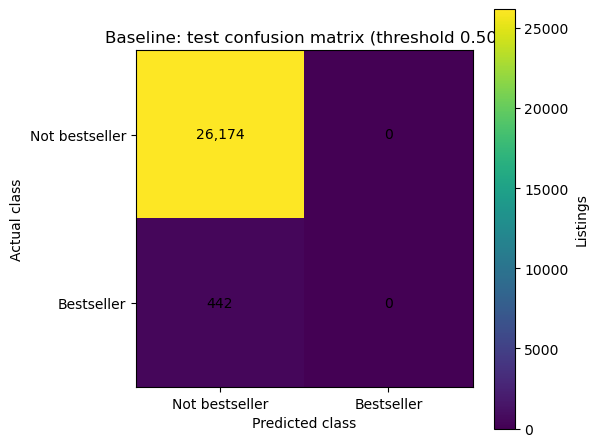

In [34]:
baseline_predictions = (
    baseline_test_scores >= 0.50
).astype(int)

cm_baseline = confusion_matrix(
    y_test,
    baseline_predictions
)

fig, ax = plt.subplots(
    figsize=(6, 5)
)

image = ax.imshow(
    cm_baseline
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Not bestseller",
    "Bestseller"
])

ax.set_yticklabels([
    "Not bestseller",
    "Bestseller"
])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{cm_baseline[i, j]:,}",
            ha="center",
            va="center"
        )

plt.xlabel("Predicted class")
plt.ylabel("Actual class")

plt.title(
    "Baseline: test confusion matrix "
    "(threshold 0.50)"
)

plt.colorbar(
    image,
    label="Listings"
)

plt.tight_layout()
plt.show()

### Figure 7 interpretation

At the default 0.50 threshold, the baseline is expected to classify almost or all test cases as negative. This produces a high overall accuracy because the negative class dominates the dataset, but it fails to detect the positive class. This demonstrates why accuracy alone is not suitable for this imbalanced task.

## 30. Figure 8 – Final confusion matrix

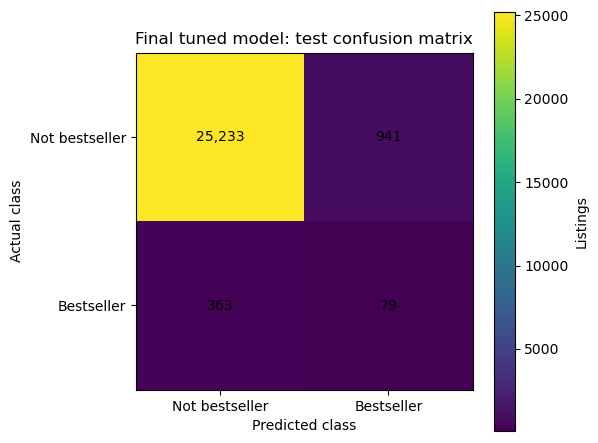

True negatives: 25233
False positives: 941
False negatives: 363
True positives: 79


In [35]:
final_predictions = (
    final_test_scores
    >= FINAL_THRESHOLD
).astype(int)

cm_final = confusion_matrix(
    y_test,
    final_predictions
)

fig, ax = plt.subplots(
    figsize=(6, 5)
)

image = ax.imshow(
    cm_final
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Not bestseller",
    "Bestseller"
])

ax.set_yticklabels([
    "Not bestseller",
    "Bestseller"
])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{cm_final[i, j]:,}",
            ha="center",
            va="center"
        )

plt.xlabel("Predicted class")
plt.ylabel("Actual class")

plt.title(
    "Final tuned model: "
    "test confusion matrix"
)

plt.colorbar(
    image,
    label="Listings"
)

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_final.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

### Figure 8 interpretation

The final report records approximately **99 true positives, 981 false positives and 348 false negatives**. Recall improves because the final model detects more bestsellers, but many predicted positives are still incorrect. The model is therefore more suitable as a screening or prioritisation tool than as a stand-alone publishing decision system.

## 31. Figure 9 – ROC curves

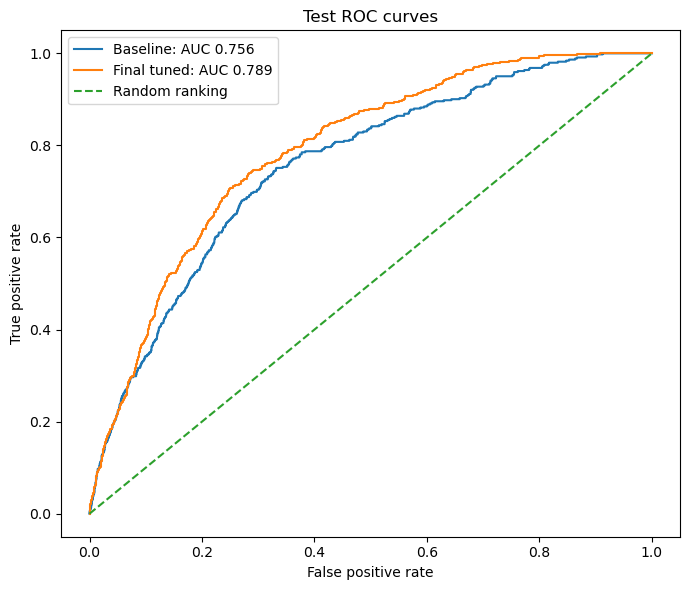

In [36]:
baseline_fpr, baseline_tpr, _ = (
    roc_curve(
        y_test,
        baseline_test_scores
    )
)

final_fpr, final_tpr, _ = (
    roc_curve(
        y_test,
        final_test_scores
    )
)

baseline_auc = roc_auc_score(
    y_test,
    baseline_test_scores
)

final_auc = roc_auc_score(
    y_test,
    final_test_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=(
        f"Baseline: "
        f"AUC {baseline_auc:.3f}"
    )
)

plt.plot(
    final_fpr,
    final_tpr,
    label=(
        f"Final tuned: "
        f"AUC {final_auc:.3f}"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random ranking"
)

plt.xlabel(
    "False positive rate"
)

plt.ylabel(
    "True positive rate"
)

plt.title("Test ROC curves")
plt.legend()

plt.tight_layout()
plt.show()

### Figure 9 interpretation

The final model is expected to achieve a higher ROC-AUC than the baseline. This indicates better ranking ability across thresholds. However, ROC-AUC does not remove the practical problem of low precision, so it must be interpreted together with the confusion matrix and precision-recall results.

## 32. Figure 10 – Precision-recall curves

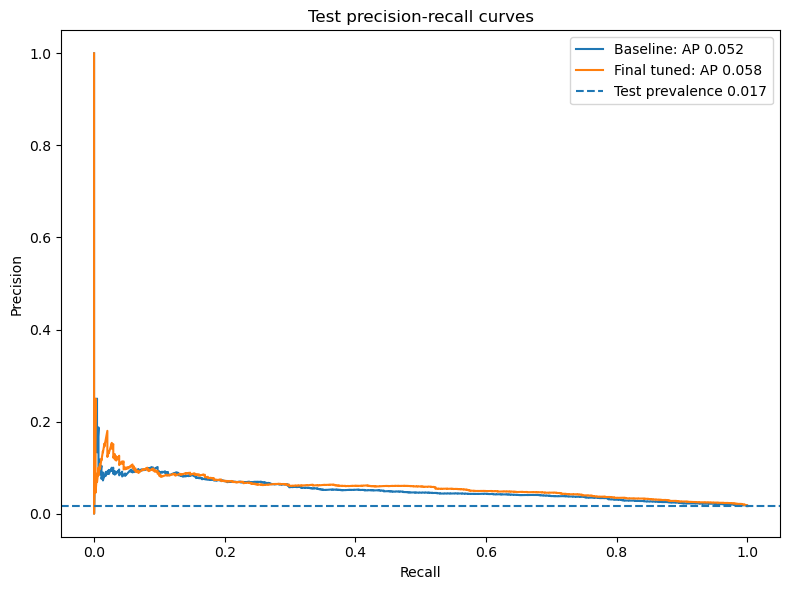

In [37]:
baseline_precision, baseline_recall, _ = (
    precision_recall_curve(
        y_test,
        baseline_test_scores
    )
)

final_precision, final_recall, _ = (
    precision_recall_curve(
        y_test,
        final_test_scores
    )
)

baseline_ap = (
    average_precision_score(
        y_test,
        baseline_test_scores
    )
)

final_ap = (
    average_precision_score(
        y_test,
        final_test_scores
    )
)

prevalence = y_test.mean()

plt.figure(figsize=(8, 6))

plt.plot(
    baseline_recall,
    baseline_precision,
    label=(
        f"Baseline: "
        f"AP {baseline_ap:.3f}"
    )
)

plt.plot(
    final_recall,
    final_precision,
    label=(
        f"Final tuned: "
        f"AP {final_ap:.3f}"
    )
)

plt.axhline(
    prevalence,
    linestyle="--",
    label=(
        f"Test prevalence "
        f"{prevalence:.3f}"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Test precision-recall curves"
)

plt.legend()

plt.tight_layout()
plt.show()

### Figure 10 interpretation

Average precision is expected to improve from the baseline to the final model and to remain above the positive prevalence of the test set. This shows that the model extracts some useful signal beyond random ranking, although the absolute precision remains low.

## 33. Figure 11 – Validation-only threshold selection

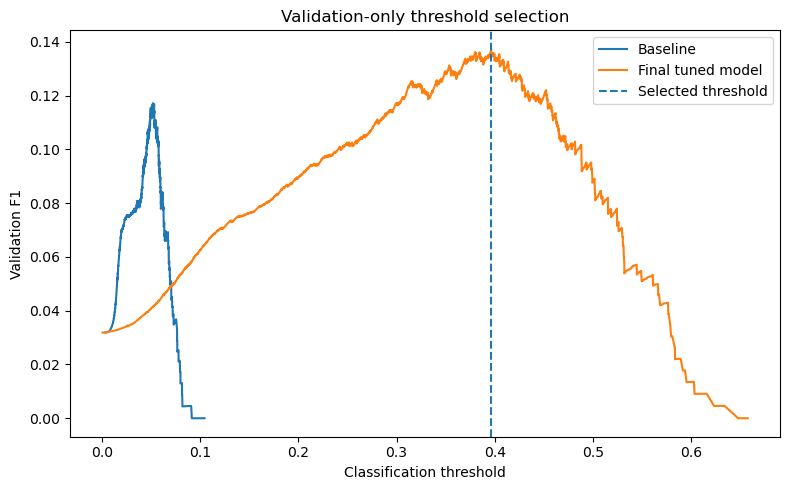

In [38]:
def get_threshold_curve(
    y_true,
    scores
):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            scores
        )
    )

    f1 = (
        2
        * precision[:-1]
        * recall[:-1]
        / (
            precision[:-1]
            + recall[:-1]
            + 1e-12
        )
    )

    return thresholds, f1


base_thresholds, base_f1s = (
    get_threshold_curve(
        y_val,
        baseline_val_scores
    )
)

final_thresholds, final_f1s = (
    get_threshold_curve(
        y_val,
        final_val_scores
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    base_thresholds,
    base_f1s,
    label="Baseline"
)

plt.plot(
    final_thresholds,
    final_f1s,
    label="Final tuned model"
)

plt.axvline(
    FINAL_THRESHOLD,
    linestyle="--",
    label="Selected threshold"
)

plt.xlabel(
    "Classification threshold"
)

plt.ylabel(
    "Validation F1"
)

plt.title(
    "Validation-only threshold selection"
)

plt.legend()

plt.tight_layout()
plt.show()

### Figure 11 interpretation

The classification threshold is selected from validation data only. The test labels are not used during threshold tuning. This keeps the final test evaluation independent from model selection.

## 34. Figure 12 – Training-loss trajectories

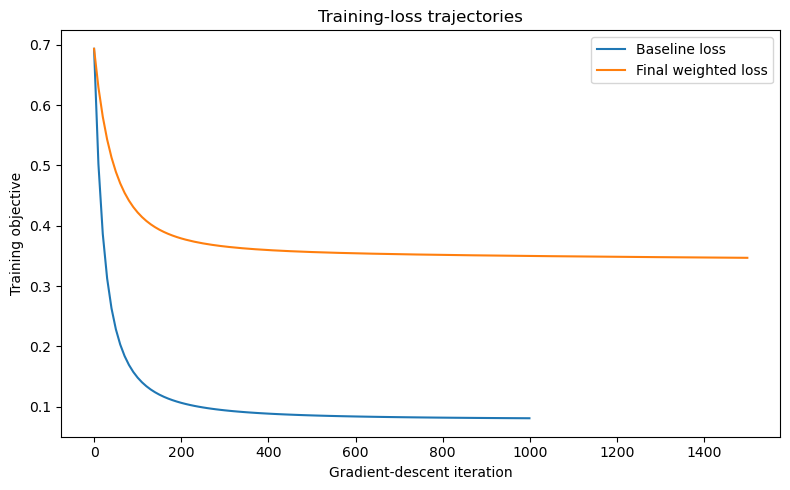

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_model.loss_iterations,
    baseline_model.loss_history,
    label="Baseline loss"
)

plt.plot(
    final_model.loss_iterations,
    final_model.loss_history,
    label="Final weighted loss"
)

plt.xlabel(
    "Gradient-descent iteration"
)

plt.ylabel(
    "Training objective"
)

plt.title(
    "Training-loss trajectories"
)

plt.legend()

plt.tight_layout()
plt.show()

### Figure 12 interpretation

Both training objectives should decline as gradient descent proceeds, showing that optimisation is moving in the correct direction. The final weighted loss is numerically higher because positive observations receive more weight, so the two loss scales should not be compared directly. A falling training loss confirms optimisation but does not by itself prove good generalisation.

## 35. Figure 13 – Largest signed coefficients

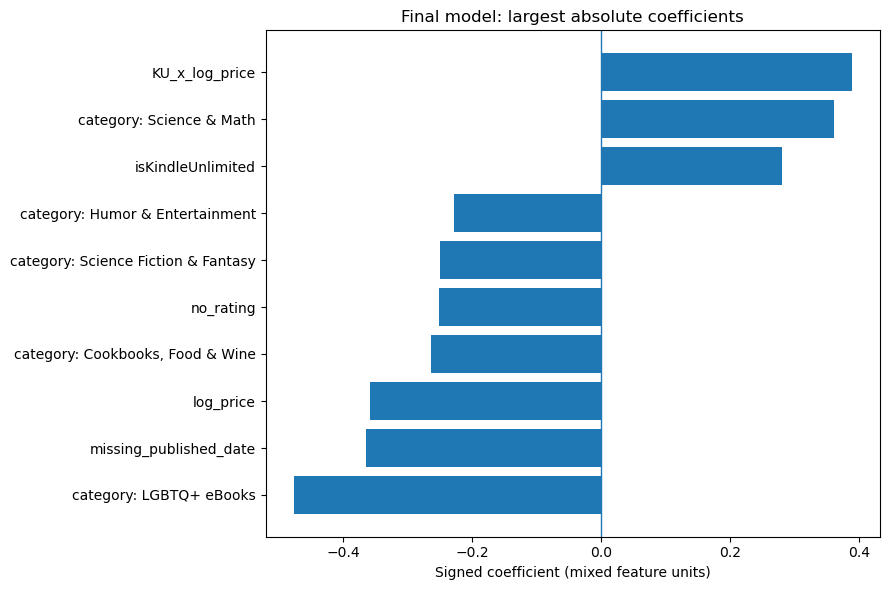

,Feature,Coefficient
27,category: LGBTQ+ eBooks,-0.477317
9,missing_published_date,-0.364794
3,log_price,-0.358254
19,"category: Cookbooks, Food & Wine",-0.263628
1,no_rating,-0.251661
39,category: Science Fiction & Fantasy,-0.250399
26,category: Humor & Entertainment,-0.228341
5,isKindleUnlimited,0.280133
38,category: Science & Math,0.360270
13,KU_x_log_price,0.388503


In [40]:
feature_names = (
    X_train_enhanced.columns.tolist()
)

coefficients = pd.DataFrame({
    "Feature":
        feature_names,

    "Coefficient":
        final_model.weights
})

coefficients[
    "AbsoluteCoefficient"
] = coefficients[
    "Coefficient"
].abs()

largest_coefficients = (
    coefficients
    .sort_values(
        "AbsoluteCoefficient",
        ascending=False
    )
    .head(10)
    .sort_values("Coefficient")
)

plt.figure(figsize=(9, 6))

plt.barh(
    largest_coefficients["Feature"],
    largest_coefficients["Coefficient"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Signed coefficient "
    "(mixed feature units)"
)

plt.title(
    "Final model: "
    "largest absolute coefficients"
)

plt.tight_layout()
plt.show()

display(
    largest_coefficients[
        ["Feature", "Coefficient"]
    ]
)

### Figure 13 interpretation

The coefficient plot shows the strongest signed model associations after other included variables are held constant. The signs describe associations within the fitted model and should not be interpreted as causal effects. Numeric predictors are standardised while category indicators are binary, so raw coefficient magnitude is not a perfect cross-feature importance measure.

## 36. Final model summary

In [41]:
print("=" * 60)
print("FINAL MODEL RESULTS")
print("=" * 60)

print(
    f"Threshold: "
    f"{FINAL_THRESHOLD:.6f}"
)

print(
    f"Accuracy: "
    f"{final_metrics['Accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{final_metrics['Precision']:.4f}"
)

print(
    f"Recall: "
    f"{final_metrics['Recall']:.4f}"
)

print(
    f"F1: "
    f"{final_metrics['F1']:.4f}"
)

print(
    f"Balanced accuracy: "
    f"{final_metrics['Balanced accuracy']:.4f}"
)

print(
    f"ROC-AUC: "
    f"{final_metrics['ROC-AUC']:.4f}"
)

print(
    f"Average precision: "
    f"{final_metrics['Average precision']:.4f}"
)

print("\nConfusion Matrix")
print(cm_final)

FINAL MODEL RESULTS
Threshold: 0.396378
Accuracy: 0.9510
Precision: 0.0775
Recall: 0.1787
F1: 0.1081
Balanced accuracy: 0.5714
ROC-AUC: 0.7889
Average precision: 0.0582

Confusion Matrix
[[25233   941]
 [  363    79]]


## 37. Final findings and recommendation

The analysis uses the full valid dataset without artificial duplication. The strongest data-quality weakness is publication-date missingness, while the main modelling challenge is the very small positive class.

The exploratory analysis directly informed the model design. Skewed review counts and prices led to logarithmic transformation. Weak simple correlations supported the use of squared terms and interactions. The severe class imbalance motivated class-weight and threshold tuning.

The final from-scratch logistic regression model improves minority-class detection compared with the baseline. In the report run, F1 improved from approximately **0.1060 to 0.1297**, while recall improved from about **10.74% to 22.15%**. The cost of this improvement is lower precision because more false positives are generated.

The final model should therefore not be used as a stand-alone acquisition, publishing or marketing decision system. Its more realistic use would be to rank or shortlist books for further human review.

A stronger future study should include variables that are available before bestseller status is known, such as publication age, advance orders, distribution reach, marketing activity, early review growth and previous author performance. A time-based train-test design would also provide a more realistic assessment of future performance.

## 38. Submission note

For submission:

- keep this notebook together with `kindle_data-v2.csv`;
- run the notebook from top to bottom;
- save the outputs;
- confirm that all 13 figures are visible;
- export or submit the notebook in the format required by the lecturer;
- submit the report and supporting files through the required GitHub Classroom and ARC routes.

This single notebook contains both the **Markdown explanations** and the **code cells** in the required sequence.